In [1]:
import sys
import os
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import numpy as np
import torch
import random
import torch.nn.functional as F

In [2]:
def read_parameters(file_path):
    params = {}

    # First pass: read and store values as strings
    with open(file_path, 'r') as file:
        for line in file:
            # Skip empty lines and comments (if any)
            line = line.strip()
            if line and not line.startswith('#'):
                # Split the line at the equals sign
                key, value = line.split('=')
                key = key.strip()
                value = value.strip()

                # Store the parameter as a string for now
                params[key] = value

    # Second pass: evaluate expressions and convert values
    for key, value in params.items():
        try:
            # Try to evaluate the value as a Python expression using previously defined parameters
            params[key] = eval(value, {}, params)
        except:
            # If it's not an expression, check if it can be converted to float or int
            if '.' in value:
                params[key] = float(value)
            else:
                params[key] = int(value)
        
        # Set the variable in the global namespace with the evaluated value
        globals()[key] = params[key]

    return params

In [3]:
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from ants_move import *
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../../..")))

pygame 2.6.1 (SDL 2.28.4, Python 3.13.3)
Hello from the pygame community. https://www.pygame.org/contribute.html


/home/alepitt/Explorables/.venv/lib/python3.13/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


In [4]:
work_folder = 'edge_spen'
saving_folder = 'l3'
os.chdir(work_folder)

In [5]:
file_path = saving_folder + '/parameters.txt'  # Path to the parameters file
parameters = read_parameters(file_path)

for key, value in parameters.items():
    print(f"{key} = {value}")

n = 300
Lx = 32
Ly = 32
delta = 0.3
beta = 4.5
eta = 0.01
decay_rate = 0.015
eta_special = 1
n_special = 30
t_transient = 200
tmax = 1200
batch_size = 60
gamma = 0.99
state_dim = (4, 9, 9)
action_dim = 8
action_bound = 1
vision = 9
actor_lr = 5e-06
critic_lr = 5e-05
weight_decay = 0.0
clip_epsilon = 0.2
entropy_coeff = 0.05
policy_steps = 1000
learning_steps = 1
clip_grad = False
use_gae = True
lam = 0.95


In [6]:
delta_list = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
beta_list = [3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5]

In [7]:
vision=state_dim[-1]
from ppo_ants import *

In [8]:
def setup_environment(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
                        tmax, n_special, t_transient, vision,
                        gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay,
                        clip_epsilon, entropy_coeff, policy_steps, learning_steps,
                        state_dim, action_dim, clip_grad,
                        alpha):
    
    env = Ants(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
            tmax, n_special, t_transient, vision=state_dim[-1])
    
    sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../../..")))

    config_net_file = f"{saving_folder}/networks.yaml"
    ppo_ants = PPO_ants( env,
                    gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay, config_net_file,
                    clip_epsilon, entropy_coeff, policy_steps, learning_steps,
                    state_dim, action_dim, clip_grad,
                    alpha)

    return env, ppo_ants

In [9]:
env, ppo_ants = setup_environment(
    n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
    tmax, n_special, t_transient, vision,
    gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay,
    clip_epsilon, entropy_coeff, policy_steps, learning_steps,
    state_dim, action_dim, clip_grad, 0.0
)

In [10]:
critic_test = 'weights/critic.pth'
actor_test = 'weights/actor.pth'

In [11]:
def load_policy_weights(ppo_ants, actor_test, critic_test):
    if not os.path.exists(f"{saving_folder}/{critic_test}"):
        print(f"Warning: {critic_test} or {actor_test} not found in {saving_folder}. Using default weights.")
    else:
        ppo_ants.critic.load_state_dict(torch.load(f"{saving_folder}/{critic_test}", weights_only=True))
        ppo_ants.actor.load_state_dict(torch.load(f"{saving_folder}/{actor_test}", weights_only=True))

In [12]:
n_special = 10

positions = np.zeros((len(beta_list), len(delta_list), n+n_special, 2))
pheromones = np.zeros((len(beta_list), len(delta_list), env.Lx, env.Ly))

for beta in beta_list:
    for delta in delta_list:
        print(f"Testing with delta = {delta}, beta = {beta}")

        env, ppo_ants = setup_environment(
            n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
            tmax, n_special, t_transient, vision,
            gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay,
            clip_epsilon, entropy_coeff, policy_steps, learning_steps,
            state_dim, action_dim, clip_grad,
            0.0
        )

        ppo_ants.setup_networks()

        load_policy_weights(ppo_ants, actor_test, critic_test)

        ppo_ants.env.reset_objects()
        ppo_ants.env.transient()
        results = ppo_ants.test_episode(max_prob=False, save_pos = True)

        final_positions = ppo_ants.env.positions.copy()
        final_field = ppo_ants.env.pheromones.copy()

        positions[beta_list.index(beta), delta_list.index(delta), :, :] = final_positions
        pheromones[beta_list.index(beta), delta_list.index(delta), :, :] = final_field

Testing with delta = 0.3, beta = 3.5
Testing with delta = 0.4, beta = 3.5
Testing with delta = 0.5, beta = 3.5
Testing with delta = 0.6, beta = 3.5
Testing with delta = 0.7, beta = 3.5
Testing with delta = 0.8, beta = 3.5
Testing with delta = 0.3, beta = 4.5
Testing with delta = 0.4, beta = 4.5
Testing with delta = 0.5, beta = 4.5
Testing with delta = 0.6, beta = 4.5
Testing with delta = 0.7, beta = 4.5
Testing with delta = 0.8, beta = 4.5
Testing with delta = 0.3, beta = 5.5
Testing with delta = 0.4, beta = 5.5
Testing with delta = 0.5, beta = 5.5
Testing with delta = 0.6, beta = 5.5
Testing with delta = 0.7, beta = 5.5
Testing with delta = 0.8, beta = 5.5
Testing with delta = 0.3, beta = 6.5
Testing with delta = 0.4, beta = 6.5
Testing with delta = 0.5, beta = 6.5
Testing with delta = 0.6, beta = 6.5
Testing with delta = 0.7, beta = 6.5
Testing with delta = 0.8, beta = 6.5
Testing with delta = 0.3, beta = 7.5
Testing with delta = 0.4, beta = 7.5
Testing with delta = 0.5, beta = 7.5
T

In [13]:
save = True
if save:
    np.savez_compressed(
    f"simulation_results_{saving_folder}_{n_special}.npz",
    positions=positions,
    pheromones=pheromones,
    )

In [14]:
load = True
if load:
    data = np.load(f"simulation_results_{saving_folder}_{n_special}.npz")
    positions = data["positions"]
    pheromones = data["pheromones"]

In [15]:
def beta_crit(d, s0):
    return 1 + 1/s0 + 2*d + d*s0 + d**2*s0

s0 = (n*eta)/(decay_rate*Lx**2)

In [16]:
from matplotlib.gridspec import GridSpec

def plot_pheromone_field(field, beta_list, delta_list, cmap='YlGnBu', field_name='pheromone'):
    fig = plt.figure(figsize=(6,8))
    gs = GridSpec(len(beta_list), len(delta_list), figure=fig)

    # subplot della griglia
    ax = np.empty((len(beta_list), len(delta_list)), dtype=object)
    for i in range(len(beta_list)):
        for j in range(len(delta_list)):
            ax[i,j] = fig.add_subplot(gs[i,j])
            ax[i,j].imshow(np.log(field[len(beta_list)-i-1,j][::-1]+1e-10), cmap=cmap,
                            vmin=min(np.log(field+1e-2).flatten()), vmax=max(np.log(field+1e-2).flatten()))
            ax[i,j].set_xticks([])
            ax[i,j].set_yticks([])
            if j == 0:
                ax[i,j].set_ylabel(f'{beta_list[len(beta_list)-i-1]}', fontsize=10)
            if i == len(beta_list)-1:
                ax[i,j].set_xlabel(f'{delta_list[j]}', fontsize=10)

    # asse globale che copre tutto il gridspec
    ax_curve = fig.add_subplot(gs[:,:], frameon=False)
    ax_curve.plot(delta_list, [beta_crit(d, s0) for d in delta_list],
                color='red', linestyle='--', linewidth=2)
    ax_curve.set_xlim(min(delta_list), max(delta_list))
    ax_curve.set_ylim(min(beta_list), max(beta_list))
    ax_curve.set_xticks([])
    ax_curve.set_yticks([])

    fig.text(-0.03, 0.52, r'$\beta$', fontsize=15, va='center', rotation='vertical')
    #fig.text(-0.06, 0.52, r'decreasing noise -->', fontsize=10, va='center', rotation='vertical')
    fig.text(0.52, -0.03, r'$\delta$', fontsize=15, ha='center')
    #fig.text(0.52, -0.06, r'decreasing sensory capacity -->', fontsize=10, ha='center')
    # title('Final positions of the ants', fontsize=16)
    fig.text(0.5, 1.02, f'Final {field_name} field (abm-ants and smart-agents)', fontsize=12, ha='center')

    plt.tight_layout()
    plt.show()

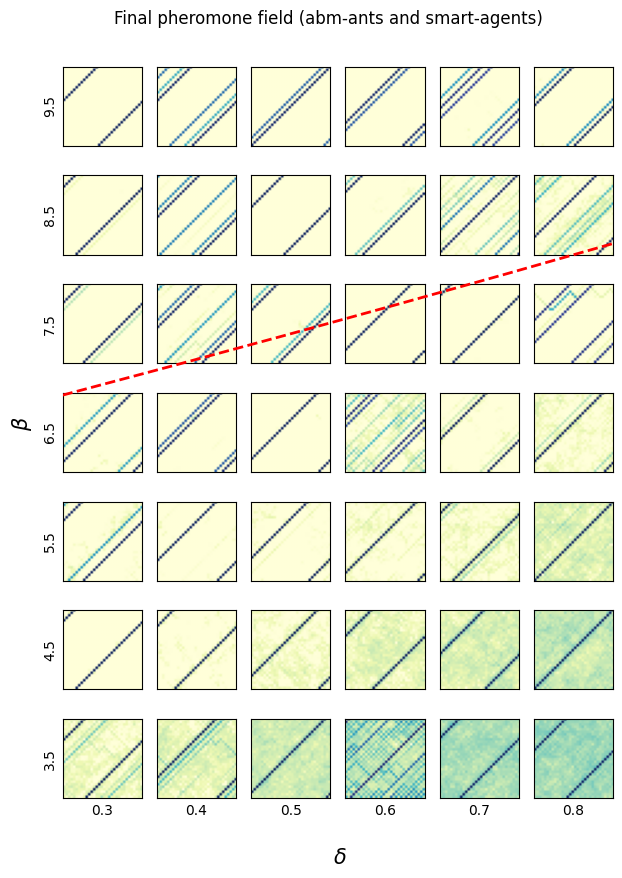

In [17]:
plot_pheromone_field(pheromones, beta_list, delta_list, cmap='YlGnBu', field_name='pheromone')

In [18]:
from matplotlib.gridspec import GridSpec

def plot_density_field(field, beta_list, delta_list, cmap='binary', field_name='density'):
    fig = plt.figure(figsize=(6,8))
    gs = GridSpec(len(beta_list), len(delta_list), figure=fig)

    # subplot della griglia
    ax = np.empty((len(beta_list), len(delta_list)), dtype=object)
    for i in range(len(beta_list)):
        for j in range(len(delta_list)):
            ax[i,j] = fig.add_subplot(gs[i,j])
            ax[i,j].imshow(np.log(field[len(beta_list)-i-1,j][::-1]+1e-10), cmap=cmap,
                            vmin=min(np.log(field+1e-1).flatten()), vmax=max(np.log(field+1e-1).flatten()))
            ax[i,j].set_xticks([])
            ax[i,j].set_yticks([])
            if j == 0:
                ax[i,j].set_ylabel(f'{beta_list[len(beta_list)-i-1]}', fontsize=10)
            if i == len(beta_list)-1:
                ax[i,j].set_xlabel(f'{delta_list[j]}', fontsize=10)

    # asse globale che copre tutto il gridspec
    ax_curve = fig.add_subplot(gs[:,:], frameon=False)
    ax_curve.plot(delta_list, [beta_crit(d, s0) for d in delta_list],
                color='red', linestyle='--', linewidth=2)
    ax_curve.set_xlim(min(delta_list), max(delta_list))
    ax_curve.set_ylim(min(beta_list), max(beta_list))
    ax_curve.set_xticks([])
    ax_curve.set_yticks([])

    fig.text(-0.03, 0.52, r'$\beta$', fontsize=15, va='center', rotation='vertical')
    #fig.text(-0.06, 0.52, r'decreasing noise -->', fontsize=10, va='center', rotation='vertical')
    fig.text(0.52, -0.03, r'$\delta$', fontsize=15, ha='center')
    #fig.text(0.52, -0.06, r'decreasing sensory capacity -->', fontsize=10, ha='center')
    # title('Final positions of the ants', fontsize=16)
    fig.text(0.5, 1.02, f'Final {field_name} field (abm-ants and smart-agents)', fontsize=12, ha='center')

    plt.tight_layout()
    plt.show()

In [19]:
def comput_position_field(positions, env):
    # converti le posizioni 2D in indici piatti
    flat_idx = (positions[..., 0] * env.Ly + positions[..., 1]).astype(int)

    # matrice one-hot (N1, N2, N3, Lx*Ly)
    onehot = np.eye(env.Lx * env.Ly)[flat_idx]

    # somma lungo la terza asse
    position_field = onehot.sum(axis=2).reshape(
        positions.shape[0], positions.shape[1], env.Lx, env.Ly
    )
    return position_field

position_field = comput_position_field(positions, env)


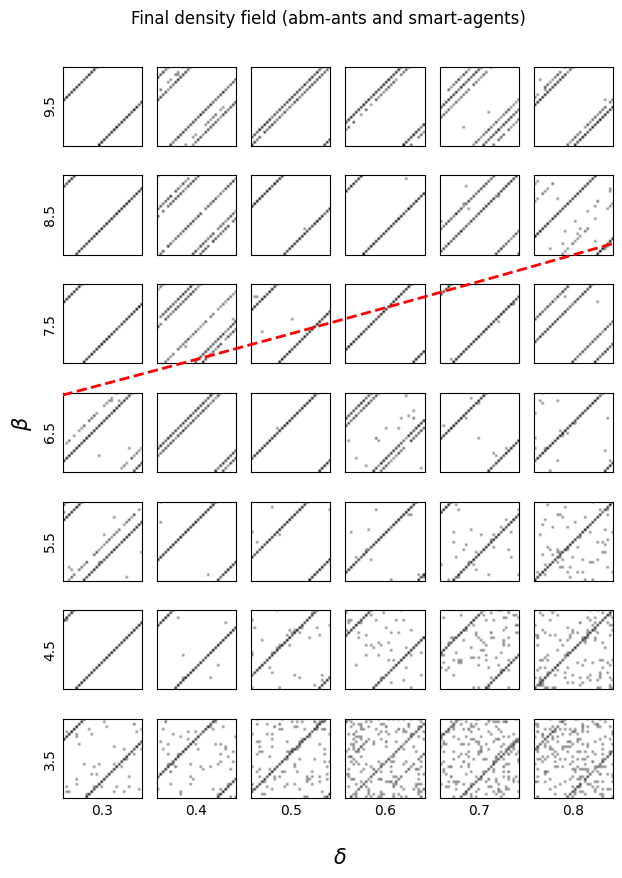

In [20]:
plot_density_field(position_field, beta_list, delta_list, cmap='binary', field_name='density')